<a href="https://colab.research.google.com/github/wenh08/Python_projects-/blob/main/Hospital_Inpatient_Discharge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this project, I've imported 400K rows of hospital data in order to give an analysis of hospilizations.

Research Questions

1. Which diagnosis categories account for the highest number of hospital discharges in New York State in 2024?

2. which medical condiions have the highest average treatment cost ?

3. which medical conditions have the longest hosptial stays ?

4. How does illness serverity affect treatment costs within the same diagonous-related group?

5. How do hospitalization patterns, costs, and lengths of stay differ across patient demographics?

6. How do hospitals compare in terms of treatment costs, discharge volume, and length of stay?


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO
import gc

from google.colab import drive

drive.mount("/content/drive")

# Setting quoting=3 (csv.QUOTE_NONE) to ignore unclosed quotation marks causing EOF errors

# Load the saved dataset in future sessions
df = pd.read_csv(
    "/content/drive/MyDrive/Hospital_2024_400K.csv",
    low_memory=False
)

# Permanently save the working dataset in Google Drive
df.to_csv(
    "/content/drive/MyDrive/Hospital_2024_400K.csv",
    index=False
)

print("Saved successfully!")
print(df.shape)



Mounted at /content/drive
Saved successfully!
(400000, 33)


In [ ]:
df.head(10)



,Health Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,New York,7002020.0,1453.0,MEMORIAL HOSPITAL FOR CANCER AND ALLIED DISEASES,50-69,125,M,White,Not Span/Hispanic,...,Extreme,Extreme,Medical,Blue Cross/Blue Shield,NaN,NaN,NaN,Y,449321.39,145177.97
1,Hudson Valley,Westchester,5957001.0,1139.0,WESTCHESTER MEDICAL CENTER,50-69,125,M,White,Not Span/Hispanic,...,Extreme,Major,Surgical,Medicare,Private Health Insurance,NaN,NaN,N,1118813.45,192747.71
2,Long Island,Suffolk,5157003.0,943.0,ST CATHERINE OF SIENA HOSPITAL,70 or Older,NaN,F,Other Race,Not Span/Hispanic,...,Moderate,Minor,Surgical,Medicare,Blue Cross/Blue Shield,Private Health Insurance,NaN,N,111718.78,21940.79
3,New York City,New York,7002054.0,1464.0,NEW YORK-PRESBYTERIAN HOSPITAL - COLUMBIA PRES...,70 or Older,100,F,Other Race,Spanish/Hispanic,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,Y,109000.53,21478.63
4,Long Island,Suffolk,5154000.0,924.0,SOUTH SHORE UNIVERSITY HOSPITAL,50-69,117,M,Other Race,Spanish/Hispanic,...,Minor,Minor,Surgical,Miscellaneous/Other,NaN,NaN,NaN,N,63682.26,24109.54
5,New York City,Bronx,7000006.0,3058.0,MONTEFIORE MED CENTER - JACK D WEILER HOSP OF ...,70 or Older,104,F,Other Race,Spanish/Hispanic,...,Minor,Moderate,Medical,Medicare,Medicaid,NaN,NaN,Y,41245.13,7166.43
6,New York City,Bronx,7000001.0,1178.0,BRONXCARE HOSPITAL CENTER,50-69,NaN,M,Black/African American,Not Span/Hispanic,...,Extreme,Extreme,Medical,Medicaid,Medicaid,NaN,NaN,N,41960.70,31440.30
7,New York City,New York,7002024.0,1456.0,MOUNT SINAI HOSPITAL,0-17,112,M,White,Not Span/Hispanic,...,Minor,Minor,Medical,Private Health Insurance,NaN,NaN,3000,N,23243.00,1902.74
8,New York City,New York,7002020.0,1453.0,MEMORIAL HOSPITAL FOR CANCER AND ALLIED DISEASES,50-69,104,F,Other Race,Not Span/Hispanic,...,Minor,Minor,Surgical,Private Health Insurance,NaN,NaN,NaN,N,104189.39,41552.78
9,Central NY,Onondaga,3301003.0,630.0,ST. JOSEPH'S HOSPITAL HEALTH CENTER,50-69,136,M,White,Not Span/Hispanic,...,Major,Extreme,Surgical,Federal/State/Local/VA,NaN,NaN,NaN,N,110229.25,75709.84


In [ ]:
df.tail(10)



,Health Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code,Gender,Race,Ethnicity,...,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
399990,Hudson Valley,Westchester,5957001.0,1139.0,WESTCHESTER MEDICAL CENTER,18-29,105,F,Other Race,Unknown,...,Major,Minor,Medical,Medicaid,Medicaid,NaN,NaN,Y,336424.38,54822.42
399991,Capital/Adirondacks,Albany,101004.0,5.0,ST. PETER'S HOSPITAL,50-69,121,M,White,Not Span/Hispanic,...,Major,Major,Medical,Private Health Insurance,NaN,NaN,NaN,Y,58331.08,23604.23
399992,Long Island,Nassau,2950002.0,528.0,NASSAU UNIVERSITY MEDICAL CENTER,30-49,115,F,Other Race,Spanish/Hispanic,...,Moderate,Minor,Medical,Medicaid,Self-Pay,NaN,NaN,N,17911.37,6442.74
399993,New York City,New York,7002053.0,1463.0,NYU LANGONE HOSPITALS,70 or Older,112,M,White,Not Span/Hispanic,...,Major,Moderate,Medical,Medicare,Medicaid,NaN,NaN,Y,92606.23,33722.32
399994,New York City,New York,7002032.0,1469.0,MOUNT SINAI MORNINGSIDE,70 or Older,100,F,Black/African American,Not Span/Hispanic,...,Moderate,Major,Medical,Medicare,NaN,NaN,NaN,Y,118016.23,23503.22
399995,New York City,Richmond,7004003.0,1740.0,STATEN ISLAND UNIVERSITY HOSP-NORTH,50-69,103,M,Other Race,Spanish/Hispanic,...,Extreme,Extreme,Medical,Medicare,NaN,NaN,NaN,Y,144956.89,43921.94
399996,Hudson Valley,Westchester,5907002.0,1098.0,ST. JOSEPH'S MEDICAL CENTER,50-69,107,M,Black/African American,Not Span/Hispanic,...,Minor,Minor,Medical,Medicare,Medicare,Medicaid,NaN,Y,82719.32,36958.87
399997,Central NY,Onondaga,3301008.0,636.0,CROUSE HOSPITAL,50-69,132,F,Black/African American,Not Span/Hispanic,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,Y,25992.65,10290.28
399998,Capital/Adirondacks,Albany,101000.0,1.0,ALBANY MEDICAL CENTER HOSPITAL,0-17,128,M,White,Not Span/Hispanic,...,Minor,Minor,Medical,"Managed Care, Unspecified",NaN,NaN,NaN,Y,18123.85,4483.43
399999,New York City,New York,7002001.0,1438.0,BELLEVUE HOSPITAL CENTER,30-49,100,M,Black/African American,Unknown,...,Moderate,Moderate,Medical,Medicaid,NaN,NaN,NaN,N,81604.10,38090.67


In [ ]:
# checking for missing values, naming them as missing and removing columns that have no missing values
#missing > 0

missing_report = df.isnull().sum().sort_values(ascending=False)
missing_report = missing_report[missing_report > 0]
missing_report = missing_report.to_frame(name="Missing Values")



In [ ]:
missing_report['missing %'] = (missing_report['Missing Values'] / len(df) * 100

                            ).round(2)
missing_report

,Missing Values,missing %
Birth Weight,369565,92.39
Payment Typology 3,358336,89.58
Payment Typology 2,224148,56.04
CCSR Procedure Description,120363,30.09
CCSR Procedure Code,120363,30.09
Zip Code,19961,4.99
Health Service Area,1348,0.34
Permanent Facility Id,1348,0.34
Hospital County,1348,0.34
Operating Certificate Number,1348,0.34


In [ ]:
# here i can see that that length of stay column returns a object, rather than numerical
df.dtypes



,0
Health Service Area,object
Hospital County,object
Operating Certificate Number,float64
Permanent Facility Id,float64
Facility Name,object
Age Group,object
Zip Code,object
Gender,object
Race,object
Ethnicity,object


In [ ]:
# checking the values witin the column to identify why it retusn as an object and i see that there's a row listed as '120+'

df['Length of Stay'].unique()




array(['24', '29', '3', '6', '1', '2', '5', '10', '36', '8', '4', '7',
       '37', '13', '9', '16', '77', '31', '28', '12', '14', '120+', '15',
       '97', '23', '17', '11', '22', '47', '21', '19', '20', '38', '63',
       '18', '85', '25', '53', '26', '27', '71', '61', '45', '116', '33',
       '34', '30', '39', '32', '94', '104', '35', '42', '89', '87', '79',
       '52', '57', '58', '101', '51', '82', '41', '73', '81', '83', '76',
       '50', '54', '43', '62', '59', '102', '60', '67', '40', '49', '48',
       '92', '69', '56', '46', '90', '65', '55', '109', '114', '96',
       '105', '93', '44', '64', '75', '70', '74', '84', '88', '72', '111',
       '99', '68', '95', '66', '98', '119', '100', '106', '117', '110',
       '86', '78', '91', '113', '118', '112', '80', '103', '108', '107',
       '115'], dtype=object)

In [ ]:
# now i convert all occurances of '120+' in length as ''

df['Length of Stay'] = pd.to_numeric(
   df['Length of Stay'].str.replace('+', '', regex=False)

)

In [ ]:
df.dtypes

,0
Health Service Area,object
Hospital County,object
Operating Certificate Number,float64
Permanent Facility Id,float64
Facility Name,object
Age Group,object
Zip Code,object
Gender,object
Race,object
Ethnicity,object


In [ ]:
# Most hosptial stays are short, median 50 % stay is 3 days, avg stay is 6 days. (longer hospitalizations are bringing the avg up)
# Hospitial costs are right skewed, avg treatment cost 27K, while the median is 14K (expensivie hospitalizations are increasing the ave cost )


pd.set_option('display.float_format', '{:,.2f}'.format)

df[["Length of Stay", "Total Charges", "Total Costs"]].describe()






,Length of Stay,Total Charges,Total Costs
count,"400,000.00","400,000.00","400,000.00"
mean,5.94,"93,039.68","27,167.96"
std,9.10,"198,347.74","56,838.48"
min,1.00,3.18,1.43
25%,2.00,"24,272.38","7,622.35"
50%,3.00,"48,106.32","14,408.16"
75%,6.00,"96,098.23","28,376.09"
max,120.00,"16,505,368.62","4,742,944.26"


In [ ]:
# Here i am only selecting columns that are needed for my research questions a

hospital_df = df[[
     "Facility Name",
    "Hospital County",
    "Discharge Year",
    "CCSR Diagnosis Description",
    "APR DRG Code",
    "APR DRG Description",
    "APR Severity of Illness Code",
    "APR Severity of Illness Description",
    "Length of Stay",
    "Total Charges",
    "Total Costs",
    "Age Group",
     "Gender",
     "Race",
     "Ethnicity"
]].copy()






In [ ]:
# I'm renaming columns to make them more human readable

hospital_df = hospital_df.rename(columns={
    'Facility Name':'Hospital',
    'Hospital County':'County',
    'Discharge Year':'Year',
    'CCSR Diagnosis Description':'Diagnosis',
    'APR DRG Code':'DRG Code',
    'APR DRG Description':'DRG Description',
    'APR Severity of Illness Code':'Severity Code',
    'APR Severity of Illness Description':'Severity',
    'Total Charges':'Charges',
    'Total Costs':'Costs'})









In [ ]:
hospital_df.columns

Index(['Hospital', 'County', 'Year', 'Diagnosis', 'DRG Code',
       'DRG Description', 'Severity Code', 'Severity', 'Length of Stay',
       'Charges', 'Costs', 'Age Group', 'Gender', 'Race', 'Ethnicity'],
      dtype='object')

In [ ]:
hospital_df.shape

(400000, 15)

In [ ]:
hospital_df.isna().sum()

,0
Hospital,0
County,1348
Year,0
Diagnosis,0
DRG Code,0
DRG Description,0
Severity Code,0
Severity,0
Length of Stay,0
Charges,0


In [ ]:
hospital_df[['Age Group', 'Gender', 'Race', 'Ethnicity', 'Severity', 'Severity Code']].apply(pd.unique)

,0
Age Group,"[50-69, 70 or Older, 0-17, 30-49, 18-29]"
Gender,"[M, F, U]"
Race,"[White, Other Race, Black/African American, Mu..."
Ethnicity,"[Not Span/Hispanic, Spanish/Hispanic, Unknown,..."
Severity,"[Extreme, Moderate, Minor, Major, Undetermined]"
Severity Code,"[4, 2, 1, 3, 0]"


In [ ]:
hospital_df['Year'].value_counts()

,count
Year,
2024,400000


In [ ]:
# Checks for zero or negitive values within these columns to ensure the data is valid


(hospital_df[['Length of Stay', 'Charges', 'Costs']] <= 0).sum()





,0
Length of Stay,0
Charges,0
Costs,0


In [ ]:
hospital_df['Severity'].value_counts(dropna= False)


,count
Severity,
Moderate,150143
Minor,111652
Major,104885
Extreme,33227
Undetermined,93


In [ ]:
hospital_df['Severity'] = hospital_df['Severity'].replace(
    'Undetermined', 'Not Classified'
)

Which diagnosis categories account for the highest number of hospital discharges in New York State in 2024?



Among the 400,000 hospital discharge records analyzed, newborn birth hospitlizations accounted for the highest number of discharges, with 28,773 (7.19%).



This was followed by septicemia (serious infection-related hospitalizations) with 25,540 discharges(6.39%), and heart failure with 10,730 discharges (2.68%).



These findings indicate that newborn care, serious infections, and cardiovascular conditions repersent some of the most frequest reasons for hospitalization within the anaylazed sample.   









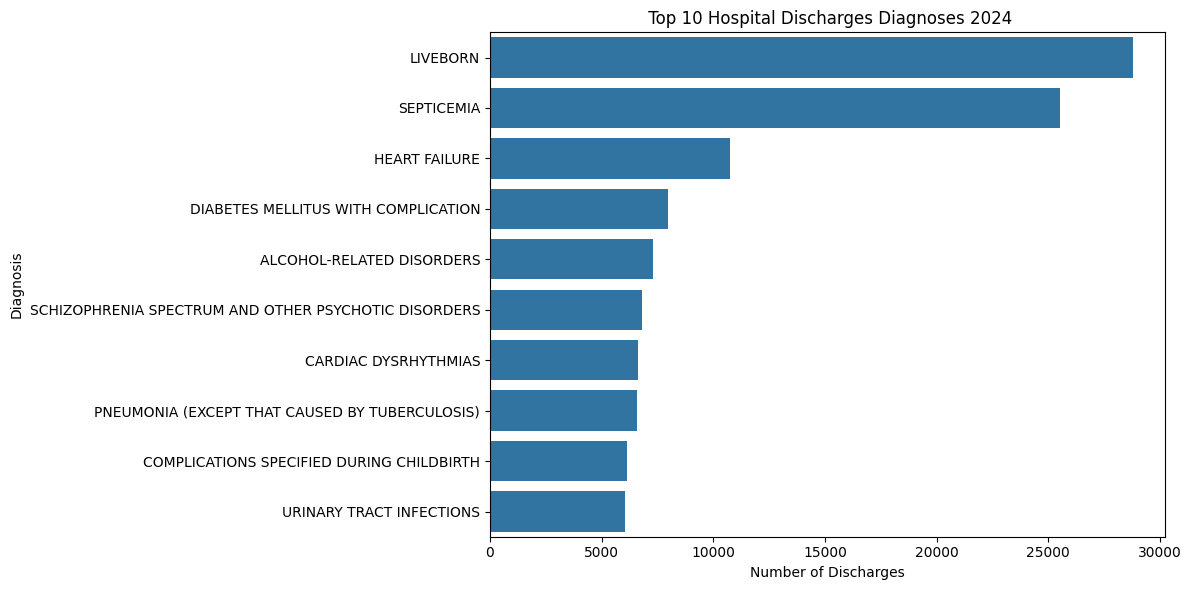

In [ ]:
top_diagnoses = hospital_df['Diagnosis'].value_counts().head(10)

plt.figure(figsize=( 12,6))

sns.barplot(
    x= top_diagnoses.values,
    y= top_diagnoses.index
)

plt.title(' Top 10 Hospital Discharges Diagnoses 2024')
plt.xlabel('Number of Discharges')
plt.ylabel('Diagnosis')
plt.tight_layout()
plt.show()




In [42]:
# DRG - Diagnosis related group
# Top 10 DGR Descriptions


hospital_df['DRG Description'].value_counts().head(10)

,count
DRG Description,
"NEONATE BIRTH WEIGHT > 2499 GRAMS, NORMAL NEWBORN OR NEONATE WITH OTHER PROBLEM",22922
SEPTICEMIA AND DISSEMINATED INFECTIONS,21633
VAGINAL DELIVERY,20934
HEART FAILURE,10344
CESAREAN SECTION WITHOUT STERILIZATION,10269
KIDNEY AND URINARY TRACT INFECTIONS,5792
OTHER PNEUMONIA,5742
SCHIZOPHRENIA,5565
MAJOR RESPIRATORY INFECTIONS AND INFLAMMATIONS,5436


Here we can see that heart and or lung transplats have the highest average treatment costs in this 2024 sample at 709,029 per discharge

In [41]:
# Average treatment cost for each DRG group sorted from the most expensive of the top 15


hospital_df.groupby('DRG Description')['Costs'].mean().sort_values(ascending= False).head(10)






,Costs
DRG Description,
HEART AND/OR LUNG TRANSPLANT,"709,029.98"
NEONATE BIRTH WEIGHT < 1500 GRAMS WITH MAJOR PROCEDURE,"592,886.31"
CHIMERIC ANTIGEN RECEPTOR (CAR) T-CELL AND OTHER IMMUNOTHERAPIES,"460,492.55"
NEONATE BIRTH WEIGHT 500-749 GRAMS WITHOUT MAJOR PROCEDURE,"452,378.65"
IMPLANTABLE HEART ASSIST SYSTEMS,"451,418.56"
NEONATE WITH ECMO,"444,845.78"
TRACHEOSTOMY WITH MV >96 HOURS WITH EXTENSIVE PROCEDURE,"422,059.41"
EXTENSIVE THIRD DEGREE BURNS WITH SKIN GRAFT,"372,162.68"
NEONATE BIRTH WEIGHT 1500-2499 GRAMS WITH MAJOR PROCEDURE,"353,081.58"


In [35]:
hospital_df.groupby('DRG Description')['Costs'].agg(["count", 'mean', 'median']
                          ).sort_values('mean', ascending= False).head(15)




,count,mean,median
DRG Description,,,
HEART AND/OR LUNG TRANSPLANT,116,"709,029.98","519,633.23"
NEONATE BIRTH WEIGHT < 1500 GRAMS WITH MAJOR PROCEDURE,34,"592,886.31","388,761.45"
CHIMERIC ANTIGEN RECEPTOR (CAR) T-CELL AND OTHER IMMUNOTHERAPIES,118,"460,492.55","412,447.54"
NEONATE BIRTH WEIGHT 500-749 GRAMS WITHOUT MAJOR PROCEDURE,42,"452,378.65","382,370.97"
IMPLANTABLE HEART ASSIST SYSTEMS,43,"451,418.56","388,315.59"
NEONATE WITH ECMO,8,"444,845.78","353,097.60"
TRACHEOSTOMY WITH MV >96 HOURS WITH EXTENSIVE PROCEDURE,500,"422,059.41","321,149.03"
EXTENSIVE THIRD DEGREE BURNS WITH SKIN GRAFT,11,"372,162.68","320,701.66"
NEONATE BIRTH WEIGHT 1500-2499 GRAMS WITH MAJOR PROCEDURE,26,"353,081.58","263,216.15"


In [39]:
hospital_df.loc[hospital_df['DRG Description'] == 'HEART AND/OR LUNG TRANSPLANT','Costs'
                  ].describe()

,Costs
count,116.00
mean,"709,029.98"
std,"619,394.21"
min,"110,746.48"
25%,"309,087.98"
50%,"519,633.23"
75%,"957,179.63"
max,"4,147,357.14"


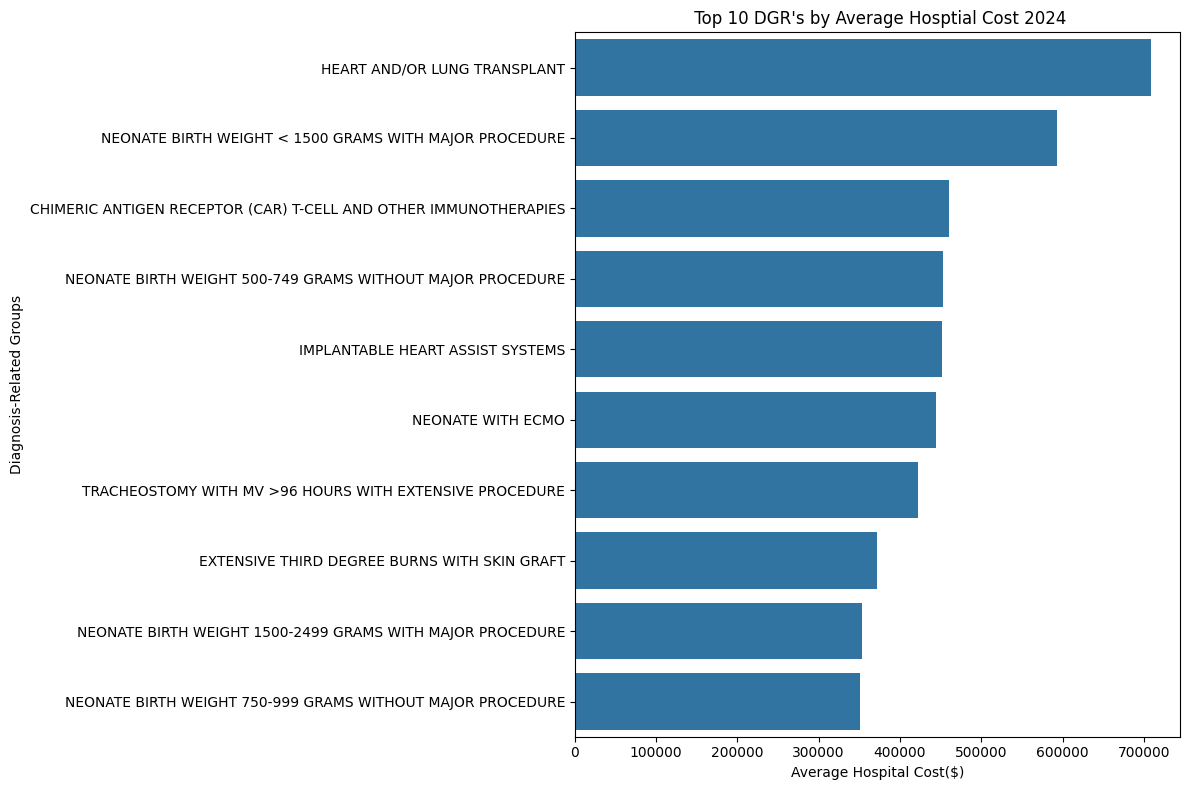

In [40]:
top_costs = (

             hospital_df.groupby('DRG Description')['Costs'].mean().sort_values(
                 ascending= False).head(10)
)
plt.figure(figsize = (12,8))

sns.barplot(

   x= top_costs.values,
   y = top_costs.index
)
plt.title(" Top 10 DGR's by Average Hosptial Cost 2024")
plt.xlabel('Average Hospital Cost($)')
plt.ylabel('Diagnosis-Related Groups')
plt.tight_layout()
plt.show()


